In [2]:
import tensorflow as tf

print("TensorFlow version:", tf.__version__)
print("GPU devices:", tf.config.list_physical_devices('GPU'))

TensorFlow version: 2.21.0
GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [3]:
!nvidia-smi

Fri Oct 30 14:53:44 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   55C    P8             12W /   70W |       3MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [4]:
import tensorflow as tf

print("TensorFlow version:", tf.__version__)
print("GPU devices:", tf.config.list_physical_devices('GPU'))

TensorFlow version: 2.21.0
GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [5]:
!nvidia-smi


Fri Oct 30 14:53:44 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   55C    P8             16W /   70W |       3MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [6]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [8]:
import os

print(os.listdir('/content/drive/MyDrive'))

['Colab Notebooks', 'give me a proper guidance to complete this in 3 d....gdoc', 'Week 1:\xa0\xa0Formalizing Proofs and Proof Paradigms.....gdoc', 'suggest some youtube resources.gdoc', 'Text Material.gdoc', 'yes.gsheet', 'now plan it according to this and also can you ed....gsheet', 'ESD_Lab_Mini_Project.docx.gdoc', 'Copy of SAPC1M4A02_Template.gdoc', 'Coursera CXRBN72MXKYR.pdf']


In [9]:
DATASET_PATH = "/content/drive/MyDrive/chest_xray"

for folder in ["train", "test"]:
    print(folder, os.listdir(os.path.join(DATASET_PATH, folder)))

FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/chest_xray/train'

In [1]:
import os

PROJECT_PATH = "/content/drive/MyDrive/DL MINI PROJECT"

print(os.listdir(PROJECT_PATH))

FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/DL MINI PROJECT'

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
import os

print(os.listdir('/content/drive/MyDrive'))

['Colab Notebooks', 'give me a proper guidance to complete this in 3 d....gdoc', 'Week 1:\xa0\xa0Formalizing Proofs and Proof Paradigms.....gdoc', 'suggest some youtube resources.gdoc', 'Text Material.gdoc', 'yes.gsheet', 'now plan it according to this and also can you ed....gsheet', 'ESD_Lab_Mini_Project.docx.gdoc', 'Copy of SAPC1M4A02_Template.gdoc', 'Coursera CXRBN72MXKYR.pdf', 'DL MINI PROJECT']


In [5]:
import os

for root, dirs, files in os.walk('/content/drive/MyDrive'):
    for folder in dirs:
        if "DL MINI PROJECT" in folder.upper():
            print("Found:", os.path.join(root, folder))

Found: /content/drive/MyDrive/DL MINI PROJECT


In [6]:
import os

PROJECT_PATH = "/content/drive/MyDrive/DL MINI PROJECT"

print("Project contents:")
print(os.listdir(PROJECT_PATH))

print("\nDataset contents:")
DATASET_PATH = os.path.join(PROJECT_PATH, "dataset")
print(os.listdir(DATASET_PATH))

Project contents:
['dataset']

Dataset contents:
['chest_xray']


In [7]:
import os

DATASET_PATH = "/content/drive/MyDrive/DL MINI PROJECT/dataset/chest_xray"

for folder in os.listdir(DATASET_PATH):
    folder_path = os.path.join(DATASET_PATH, folder)

    if os.path.isdir(folder_path):
        print(f"\n{folder}:")
        print(os.listdir(folder_path))

        for class_name in os.listdir(folder_path):
            class_path = os.path.join(folder_path, class_name)

            if os.path.isdir(class_path):
                print(class_name, ":", len(os.listdir(class_path)), "files")


val:
['.DS_Store', 'PNEUMONIA', 'NORMAL']
PNEUMONIA : 9 files
NORMAL : 9 files

train:
['.DS_Store', 'NORMAL', 'PNEUMONIA']
NORMAL : 1342 files
PNEUMONIA : 3879 files

test:
['.DS_Store', 'PNEUMONIA', 'NORMAL']
PNEUMONIA : 390 files
NORMAL : 234 files


In [8]:
import os

DATASET_PATH = "/content/drive/MyDrive/DL MINI PROJECT/dataset/chest_xray"

valid_extensions = (".jpg", ".jpeg", ".png", ".bmp")

for split in ["train", "val", "test"]:
    print(f"\n{split.upper()}")

    for category in ["NORMAL", "PNEUMONIA"]:
        folder = os.path.join(DATASET_PATH, split, category)

        images = [
            f for f in os.listdir(folder)
            if f.lower().endswith(valid_extensions)
        ]

        print(category, ":", len(images), "images")


TRAIN
NORMAL : 1341 images
PNEUMONIA : 3878 images

VAL
NORMAL : 8 images
PNEUMONIA : 8 images

TEST
NORMAL : 234 images
PNEUMONIA : 390 images


In [9]:
import tensorflow as tf
import os

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 42

train_dir = os.path.join(DATASET_PATH, "train")
test_dir = os.path.join(DATASET_PATH, "test")

train_ds = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    validation_split=0.15,
    subset="training",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary"
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    validation_split=0.15,
    subset="validation",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary"
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    test_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    shuffle=False
)

print("Classes:", train_ds.class_names)
print("Dataset loaded successfully!")

Found 5219 files belonging to 2 classes.
Using 4437 files for training.
Found 5219 files belonging to 2 classes.
Using 782 files for validation.
Found 624 files belonging to 2 classes.
Classes: ['NORMAL', 'PNEUMONIA']
Dataset loaded successfully!


In [10]:
import tensorflow as tf
import numpy as np
import os

AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)
test_ds = test_ds.prefetch(AUTOTUNE)

print("Training batches:", tf.data.experimental.cardinality(train_ds).numpy())
print("Validation batches:", tf.data.experimental.cardinality(val_ds).numpy())
print("Test batches:", tf.data.experimental.cardinality(test_ds).numpy())

Training batches: 139
Validation batches: 25
Test batches: 20


In [11]:
from tensorflow.keras.applications import DenseNet121
from tensorflow.keras.applications.densenet import preprocess_input
from tensorflow.keras import layers, Model

data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.05),
    layers.RandomZoom(0.10)
])

base_model = DenseNet121(
    include_top=False,
    weights="imagenet",
    input_shape=(224, 224, 3)
)

base_model.trainable = False

inputs = tf.keras.Input(shape=(224, 224, 3))

x = data_augmentation(inputs)
x = preprocess_input(x)
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.4)(x)
outputs = layers.Dense(1, activation="sigmoid")(x)

densenet_model = Model(inputs, outputs)

densenet_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall"),
        tf.keras.metrics.AUC(name="auc")
    ]
)

densenet_model.summary()

29084464/29084464 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential (Sequential)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ add (Add)                       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide_1 (TrueDivide)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ densenet121 (Functional)        │ (None, 7, 7, 1024)     │     7,037,504 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1024)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │         1,025 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,038,529 (26.85 MB)

 Trainable params: 1,025 (4.00 KB)

 Non-trainable params: 7,037,504 (26.85 MB)

In [13]:
RESULTS_PATH = "/content/drive/MyDrive/DL MINI PROJECT/results/densenet121"
os.makedirs(RESULTS_PATH, exist_ok=True)

MODEL_PATH = os.path.join(RESULTS_PATH, "best_densenet121.keras")

In [14]:
callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True
    ),

    tf.keras.callbacks.ModelCheckpoint(
        MODEL_PATH,
        monitor="val_loss",
        save_best_only=True
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=2,
        min_lr=1e-7
    )
]

history = densenet_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=12,
    callbacks=callbacks
)

Epoch 1/12
 40/139 ━━━━━━━━━━━━━━━━━━━━ 17:01 10s/step - accuracy: 0.5334 - auc: 0.4692 - loss: 0.8355 - precision: 0.7027 - recall: 0.5955

KeyboardInterrupt: 

In [15]:
import os

print("Model checkpoint exists:", os.path.exists(MODEL_PATH))
print("GPU:", tf.config.list_physical_devices('GPU'))

Model checkpoint exists: False
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [18]:
AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.cache().prefetch(AUTOTUNE)
val_ds = val_ds.cache().prefetch(AUTOTUNE)
test_ds = test_ds.cache().prefetch(AUTOTUNE)

In [19]:
callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=2,
        restore_best_weights=True
    ),

    tf.keras.callbacks.ModelCheckpoint(
        MODEL_PATH,
        monitor="val_loss",
        save_best_only=True
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=1,
        min_lr=1e-7
    )
]

history = densenet_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=8,
    callbacks=callbacks
)

Epoch 1/8
139/139 ━━━━━━━━━━━━━━━━━━━━ 1266s 9s/step - accuracy: 0.6822 - auc: 0.5360 - loss: 0.6716 - precision: 0.7489 - recall: 0.8588 - val_accuracy: 0.7570 - val_auc: 0.6305 - val_loss: 0.5366 - val_precision: 0.7577 - val_recall: 0.9983 - learning_rate: 1.0000e-04
Epoch 2/8
139/139 ━━━━━━━━━━━━━━━━━━━━ 26s 186ms/step - accuracy: 0.7235 - auc: 0.6356 - loss: 0.5892 - precision: 0.7723 - recall: 0.8886 - val_accuracy: 0.7839 - val_auc: 0.8315 - val_loss: 0.4566 - val_precision: 0.7794 - val_recall: 0.9966 - learning_rate: 1.0000e-04
Epoch 3/8
139/139 ━━━━━━━━━━━━━━━━━━━━ 25s 182ms/step - accuracy: 0.7523 - auc: 0.7162 - loss: 0.5242 - precision: 0.7900 - recall: 0.9066 - val_accuracy: 0.8146 - val_auc: 0.9139 - val_loss: 0.3968 - val_precision: 0.8066 - val_recall: 0.9932 - learning_rate: 1.0000e-04
Epoch 4/8
139/139 ━━━━━━━━━━━━━━━━━━━━ 25s 180ms/step - accuracy: 0.7845 - auc: 0.7757 - loss: 0.4752 - precision: 0.8150 - recall: 0.9172 - val_accuracy: 0.8581 - val_auc: 0.9439 - val

In [20]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)
import numpy as np
import tensorflow as tf

# Load the best saved model
densenet_model = tf.keras.models.load_model(MODEL_PATH)

# Actual labels
y_true = np.concatenate([
    y.numpy().ravel() for x, y in test_ds
]).astype(int)

# Predicted probabilities
y_prob = densenet_model.predict(test_ds).ravel()

# Convert probabilities into class predictions
y_pred = (y_prob >= 0.5).astype(int)

# Calculate evaluation metrics
print("Accuracy:", accuracy_score(y_true, y_pred))
print("Precision:", precision_score(y_true, y_pred))
print("Recall:", recall_score(y_true, y_pred))
print("F1 Score:", f1_score(y_true, y_pred))
print("ROC-AUC:", roc_auc_score(y_true, y_prob))

print("\nClassification Report:")
print(classification_report(
    y_true,
    y_pred,
    target_names=["NORMAL", "PNEUMONIA"]
))

20/20 ━━━━━━━━━━━━━━━━━━━━ 10s 349ms/step
Accuracy: 0.7548076923076923
Precision: 0.7223264540337712
Recall: 0.9871794871794872
F1 Score: 0.8342361863488624
ROC-AUC: 0.9368617137847907

Classification Report:
              precision    recall  f1-score   support

      NORMAL       0.95      0.37      0.53       234
   PNEUMONIA       0.72      0.99      0.83       390

    accuracy                           0.75       624
   macro avg       0.83      0.68      0.68       624
weighted avg       0.81      0.75      0.72       624



In [21]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training")
plt.plot(history.history["val_accuracy"], label="Validation")
plt.title("DenseNet121 Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training")
plt.plot(history.history["val_loss"], label="Validation")
plt.title("DenseNet121 Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()

plt.savefig(
    os.path.join(RESULTS_PATH, "densenet_training_graphs.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

NameError: name 'plt' is not defined

In [1]:
import matplotlib.pyplot as plt
import os

NameError: name 'history' is not defined

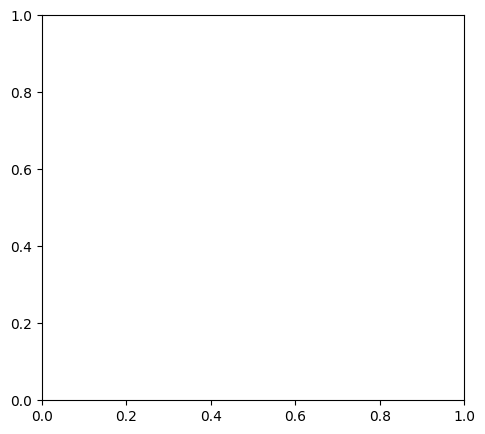

In [2]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training")
plt.plot(history.history["val_accuracy"], label="Validation")
plt.title("DenseNet121 Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training")
plt.plot(history.history["val_loss"], label="Validation")
plt.title("DenseNet121 Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()

plt.savefig(
    os.path.join(RESULTS_PATH, "densenet_training_graphs.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [3]:
import os

MODEL_PATH = "/content/drive/MyDrive/DL MINI PROJECT/results/densenet121/best_densenet121.keras"

print("Model exists:", os.path.exists(MODEL_PATH))

Model exists: False


In [4]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [5]:
import os

PROJECT_PATH = "/content/drive/MyDrive/DL MINI PROJECT"

print("Project folders:", os.listdir(PROJECT_PATH))

RESULTS_PATH = os.path.join(PROJECT_PATH, "results")

if os.path.exists(RESULTS_PATH):
    for root, dirs, files in os.walk(RESULTS_PATH):
        print("\nFolder:", root)
        print("Files:", files)
else:
    print("Results folder not found")

Project folders: ['dataset', 'results']

Folder: /content/drive/MyDrive/DL MINI PROJECT/results
Files: []

Folder: /content/drive/MyDrive/DL MINI PROJECT/results/densenet121
Files: ['best_densenet121.keras']


In [6]:
import os
import tensorflow as tf

MODEL_PATH = "/content/drive/MyDrive/DL MINI PROJECT/results/densenet121/best_densenet121.keras"

densenet_model = tf.keras.models.load_model(MODEL_PATH)

print("DenseNet121 loaded successfully!")
print("Model parameters:", densenet_model.count_params())

DenseNet121 loaded successfully!
Model parameters: 7038529


In [7]:
DATASET_PATH = "/content/drive/MyDrive/DL MINI PROJECT/dataset/chest_xray"

test_ds = tf.keras.utils.image_dataset_from_directory(
    os.path.join(DATASET_PATH, "test"),
    image_size=(224, 224),
    batch_size=32,
    label_mode="binary",
    shuffle=False
)

print("Classes:", test_ds.class_names)

Found 624 files belonging to 2 classes.
Classes: ['NORMAL', 'PNEUMONIA']


In [8]:
import numpy as np
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, classification_report,
    confusion_matrix
)

y_true = np.concatenate([
    y.numpy().ravel() for x, y in test_ds
]).astype(int)

y_prob = densenet_model.predict(test_ds).ravel()
y_pred = (y_prob >= 0.5).astype(int)

print("Accuracy:", accuracy_score(y_true, y_pred))
print("Precision:", precision_score(y_true, y_pred))
print("Recall:", recall_score(y_true, y_pred))
print("F1 Score:", f1_score(y_true, y_pred))
print("ROC-AUC:", roc_auc_score(y_true, y_prob))

print("\nClassification Report:")
print(classification_report(
    y_true, y_pred,
    target_names=["NORMAL", "PNEUMONIA"]
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_true, y_pred))

20/20 ━━━━━━━━━━━━━━━━━━━━ 14s 379ms/step
Accuracy: 0.7548076923076923
Precision: 0.7223264540337712
Recall: 0.9871794871794872
F1 Score: 0.8342361863488624
ROC-AUC: 0.9368617137847907

Classification Report:
              precision    recall  f1-score   support

      NORMAL       0.95      0.37      0.53       234
   PNEUMONIA       0.72      0.99      0.83       390

    accuracy                           0.75       624
   macro avg       0.83      0.68      0.68       624
weighted avg       0.81      0.75      0.72       624


Confusion Matrix:
[[ 86 148]
 [  5 385]]


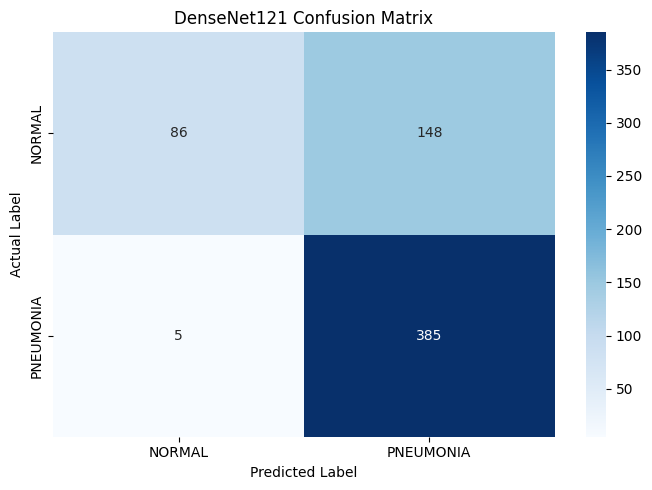

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns
import os
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["NORMAL", "PNEUMONIA"],
    yticklabels=["NORMAL", "PNEUMONIA"]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("DenseNet121 Confusion Matrix")
plt.tight_layout()

plt.savefig(
    os.path.join(RESULTS_PATH, "densenet_confusion_matrix.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [10]:
import tensorflow as tf

# Check the model architecture
print("Main model layers:")
for layer in densenet_model.layers:
    print(layer.name, type(layer).__name__)

# Access the DenseNet121 backbone
backbone = densenet_model.get_layer("densenet121")

print("\nLast convolutional layers:")
conv_layers = [
    layer for layer in backbone.layers
    if isinstance(layer, tf.keras.layers.Conv2D)
]

for layer in conv_layers[-5:]:
    print(layer.name, layer.output.shape)

Main model layers:
input_layer_1 InputLayer
sequential Sequential
densenet121 Functional
global_average_pooling2d GlobalAveragePooling2D
dropout Dropout
dense Dense

Last convolutional layers:
conv5_block14_2_conv (None, 7, 7, 32)
conv5_block15_1_conv (None, 7, 7, 128)
conv5_block15_2_conv (None, 7, 7, 32)
conv5_block16_1_conv (None, 7, 7, 128)
conv5_block16_2_conv (None, 7, 7, 32)


In [11]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import os

backbone = densenet_model.get_layer("densenet121")

target_layer = "conv5_block16_2_conv"

# Extract the selected convolutional feature maps
feature_model = tf.keras.Model(
    inputs=backbone.input,
    outputs=[
        backbone.get_layer(target_layer).output,
        backbone.output
    ]
)

augmentation = densenet_model.get_layer("sequential")
pooling = densenet_model.get_layer("global_average_pooling2d")
dropout = densenet_model.get_layer("dropout")
classifier = densenet_model.get_layer("dense")


def generate_gradcam(image, target_class=1):

    # Convert image into a batch
    image = tf.cast(image, tf.float32)
    image_batch = tf.expand_dims(image, axis=0)

    # Apply the same preprocessing as during inference
    augmented = augmentation(image_batch, training=False)
    processed = tf.keras.applications.densenet.preprocess_input(
        augmented
    )

    with tf.GradientTape() as tape:

        conv_outputs, backbone_output = feature_model(
            processed, training=False
        )

        tape.watch(conv_outputs)

        x = pooling(backbone_output)
        x = dropout(x, training=False)
        predictions = classifier(x)

        if target_class == 1:
            class_score = predictions[:, 0]
        else:
            class_score = 1.0 - predictions[:, 0]

    gradients = tape.gradient(class_score, conv_outputs)

    pooled_gradients = tf.reduce_mean(
        gradients, axis=(0, 1, 2)
    )

    conv_outputs = conv_outputs[0]

    heatmap = tf.reduce_sum(
        conv_outputs * pooled_gradients,
        axis=-1
    )

    heatmap = tf.maximum(heatmap, 0)

    max_value = tf.reduce_max(heatmap)

    heatmap = tf.where(
        max_value > 0,
        heatmap / (max_value + 1e-8),
        tf.zeros_like(heatmap)
    )

    return heatmap.numpy(), float(predictions[0, 0].numpy())

In [12]:
# Find one example of each prediction outcome
wanted_indices = {
    "TN": np.where((y_true == 0) & (y_pred == 0))[0][0],
    "FP": np.where((y_true == 0) & (y_pred == 1))[0][0],
    "FN": np.where((y_true == 1) & (y_pred == 0))[0][0],
    "TP": np.where((y_true == 1) & (y_pred == 1))[0][0]
}

examples = {}

# Extract only the four required images
start = 0

for images, labels in test_ds:
    batch = images.numpy()

    for name, index in wanted_indices.items():
        if start <= index < start + len(batch):
            examples[name] = batch[index - start]

    start += len(batch)

print("Examples extracted:", list(examples.keys()))

Examples extracted: ['TN', 'FP', 'TP', 'FN']


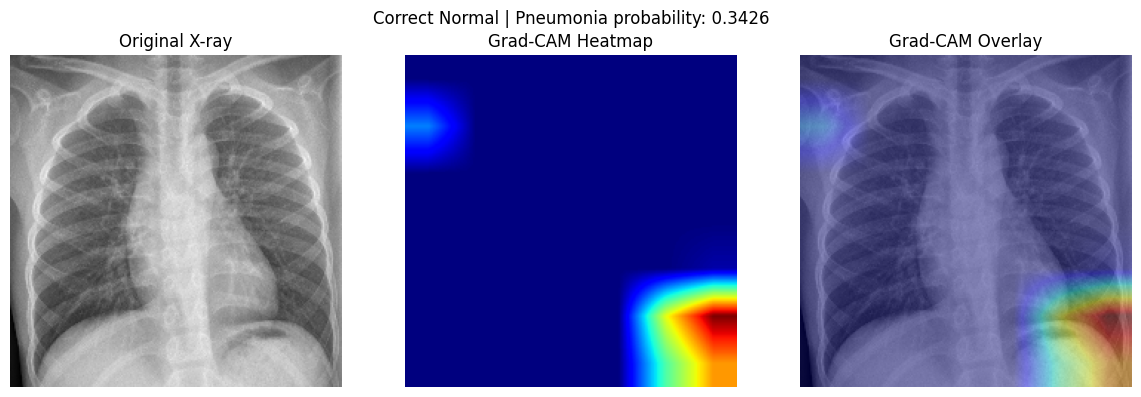

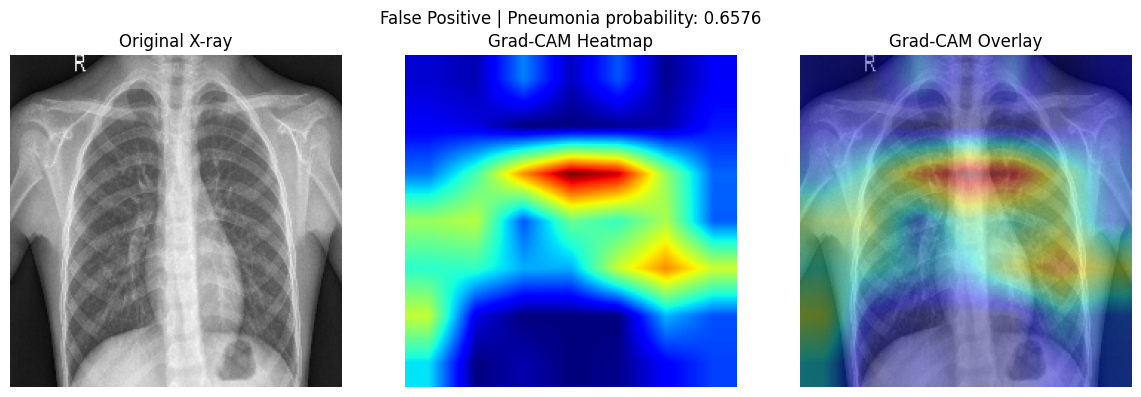

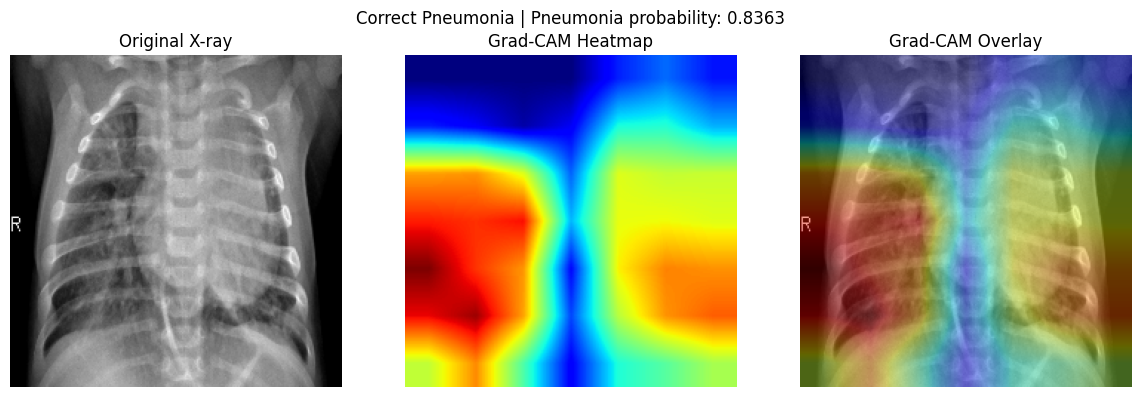

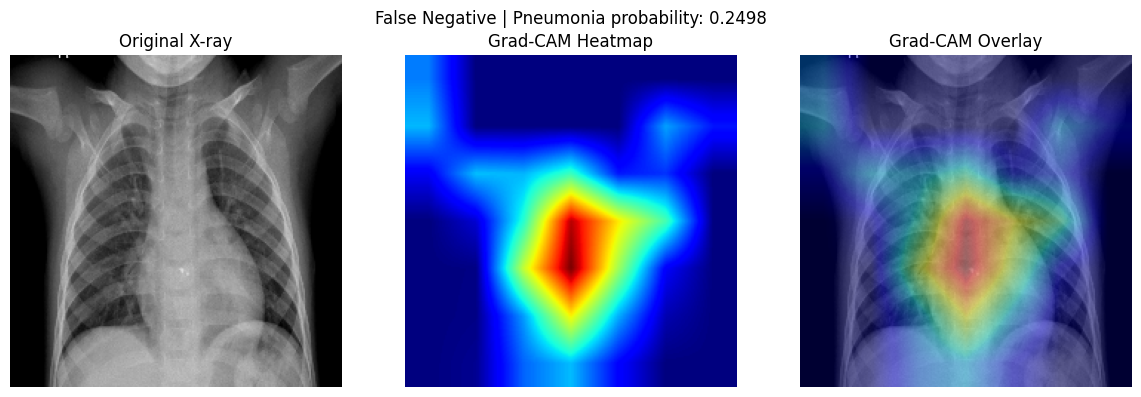

In [13]:
from PIL import Image

GRADCAM_PATH = os.path.join(RESULTS_PATH, "gradcam")
os.makedirs(GRADCAM_PATH, exist_ok=True)

names = {
    "TN": "Correct Normal",
    "TP": "Correct Pneumonia",
    "FP": "False Positive",
    "FN": "False Negative"
}

for key, image in examples.items():

    target_class = 1 if key in ["TP", "FP"] else 0

    heatmap, probability = generate_gradcam(
        image,
        target_class=target_class
    )

    # Resize heatmap to original image dimensions
    heatmap_resized = tf.image.resize(
        heatmap[..., np.newaxis],
        (224, 224)
    ).numpy().squeeze()

    plt.figure(figsize=(12, 4))

    plt.subplot(1, 3, 1)
    plt.imshow(image.astype("uint8"))
    plt.title("Original X-ray")
    plt.axis("off")

    plt.subplot(1, 3, 2)
    plt.imshow(heatmap_resized, cmap="jet")
    plt.title("Grad-CAM Heatmap")
    plt.axis("off")

    plt.subplot(1, 3, 3)
    plt.imshow(image.astype("uint8"))
    plt.imshow(heatmap_resized, cmap="jet", alpha=0.4)
    plt.title("Grad-CAM Overlay")
    plt.axis("off")

    plt.suptitle(
        f"{names[key]} | Pneumonia probability: {probability:.4f}"
    )

    plt.tight_layout()

    plt.savefig(
        os.path.join(GRADCAM_PATH, f"gradcam_{key}.png"),
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

In [16]:
import os

PROJECT_PATH = "/content/drive/MyDrive/DL MINI PROJECT"

for root, dirs, files in os.walk(os.path.join(PROJECT_PATH, "models")):
    print("\nFolder:", root)
    for file in files:
        print(file)

In [17]:
import os

PROJECT_PATH = "/content/drive/MyDrive/DL MINI PROJECT"

print("Searching project for saved models...\n")

for root, dirs, files in os.walk(PROJECT_PATH):
    for file in files:
        if file.endswith((".keras", ".h5", ".hdf5")):
            full_path = os.path.join(root, file)
            size_mb = os.path.getsize(full_path) / (1024 * 1024)

            print("Model:", file)
            print("Path:", full_path)
            print("Size:", round(size_mb, 2), "MB")
            print("-" * 40)

Searching project for saved models...

Model: best_densenet121.keras
Path: /content/drive/MyDrive/DL MINI PROJECT/results/densenet121/best_densenet121.keras
Size: 28.32 MB
----------------------------------------


In [18]:
print("DenseNet121 Model Efficiency")
print("-" * 40)

total_params = densenet_model.count_params()

trainable_params = sum(
    tf.keras.backend.count_params(w)
    for w in densenet_model.trainable_weights
)

non_trainable_params = sum(
    tf.keras.backend.count_params(w)
    for w in densenet_model.non_trainable_weights
)

model_size = os.path.getsize(MODEL_PATH) / (1024 * 1024)

print("Total parameters:", total_params)
print("Trainable parameters:", trainable_params)
print("Non-trainable parameters:", non_trainable_params)
print("Saved model size:", round(model_size, 2), "MB")

DenseNet121 Model Efficiency
----------------------------------------
Total parameters: 7038529
Trainable parameters: 1025
Non-trainable parameters: 7037504
Saved model size: 28.32 MB


In [19]:
NOTEBOOK_PATH = os.path.join(PROJECT_PATH, "notebooks")

for root, dirs, files in os.walk(NOTEBOOK_PATH):
    print("\nFolder:", root)
    for file in files:
        print(file)

In [20]:
import os

NOTEBOOK_PATH = "/content/drive/MyDrive/DL MINI PROJECT/notebooks"

print("Notebook folder exists:", os.path.exists(NOTEBOOK_PATH))

if os.path.exists(NOTEBOOK_PATH):
    print("Contents:", os.listdir(NOTEBOOK_PATH))

Notebook folder exists: False


In [21]:
import os

PROJECT_PATH = "/content/drive/MyDrive/DL MINI PROJECT"

MODEL_PATHS = {
    "Custom CNN": os.path.join(PROJECT_PATH, "models", "custom_cnn_best.keras"),
    "ResNet50": os.path.join(PROJECT_PATH, "models", "resnet50_best.keras"),
    "DenseNet121": os.path.join(PROJECT_PATH, "results", "densenet121", "best_densenet121.keras")
}

print("MODEL FILE VERIFICATION")

for name, path in MODEL_PATHS.items():
    print(name, ":", os.path.exists(path), path)

print("\nPROJECT FOLDERS:")
print(os.listdir(PROJECT_PATH))

MODEL FILE VERIFICATION
Custom CNN : False /content/drive/MyDrive/DL MINI PROJECT/models/custom_cnn_best.keras
ResNet50 : False /content/drive/MyDrive/DL MINI PROJECT/models/resnet50_best.keras
DenseNet121 : True /content/drive/MyDrive/DL MINI PROJECT/results/densenet121/best_densenet121.keras

PROJECT FOLDERS:
['dataset', 'results', 'models ']


In [22]:
import os

PROJECT_PATH = "/content/drive/MyDrive/DL MINI PROJECT"

print("Searching for model files...\n")

for root, dirs, files in os.walk(PROJECT_PATH):
    for file in files:
        if file in [
            "custom_cnn_best.keras",
            "resnet50_best.keras",
            "best_densenet121.keras"
        ]:
            print("FOUND:", file)
            print("LOCATION:", os.path.join(root, file))
            print("-" * 50)

Searching for model files...

FOUND: best_densenet121.keras
LOCATION: /content/drive/MyDrive/DL MINI PROJECT/results/densenet121/best_densenet121.keras
--------------------------------------------------
FOUND: custom_cnn_best.keras
LOCATION: /content/drive/MyDrive/DL MINI PROJECT/models /custom_cnn_best.keras
--------------------------------------------------
FOUND: resnet50_best.keras
LOCATION: /content/drive/MyDrive/DL MINI PROJECT/models /resnet50_best.keras
--------------------------------------------------


In [23]:
import os

PROJECT_PATH = "/content/drive/MyDrive/DL MINI PROJECT"

MODEL_PATHS = {
    "Custom CNN": os.path.join(PROJECT_PATH, "models ", "custom_cnn_best.keras"),
    "ResNet50": os.path.join(PROJECT_PATH, "models ", "resnet50_best.keras"),
    "DenseNet121": os.path.join(PROJECT_PATH, "results", "densenet121", "best_densenet121.keras")
}

for name, path in MODEL_PATHS.items():
    print(name, ":", os.path.exists(path))

Custom CNN : True
ResNet50 : True
DenseNet121 : True


In [24]:
import tensorflow as tf

models = {}

for name, path in MODEL_PATHS.items():
    print("Loading", name, "...")
    models[name] = tf.keras.models.load_model(path)
    print(name, "loaded successfully!")

print("\nAll three models loaded!")

Loading Custom CNN ...


TypeError: <class 'keras.src.models.sequential.Sequential'> could not be deserialized properly. Please ensure that components that are Python object instances (layers, models, etc.) returned by `get_config()` are explicitly deserialized in the model's `from_config()` method.

config={'module': 'keras', 'class_name': 'Sequential', 'config': {'name': 'sequential_1', 'trainable': True, 'dtype': {'module': 'keras', 'class_name': 'DTypePolicy', 'config': {'name': 'float32'}, 'registered_name': None, 'shared_object_id': 1955514174160}, 'layers': [{'module': 'keras.layers', 'class_name': 'InputLayer', 'config': {'batch_shape': [None, 224, 224, 3], 'dtype': 'float32', 'sparse': False, 'ragged': False, 'name': 'input_layer_1', 'optional': False}, 'registered_name': None}, {'module': 'keras', 'class_name': 'Sequential', 'config': {'name': 'data_augmentation', 'trainable': True, 'dtype': {'module': 'keras', 'class_name': 'DTypePolicy', 'config': {'name': 'float32'}, 'registered_name': None, 'shar

In [25]:
import tensorflow as tf
import keras
import sys

print("Python:", sys.version)
print("TensorFlow:", tf.__version__)
print("Keras:", keras.__version__)

Python: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
TensorFlow: 2.21.0
Keras: 3.13.2


In [26]:
%pip install -q keras==3.15.0

In [1]:
import tensorflow as tf
import keras

print("TensorFlow:", tf.__version__)
print("Keras:", keras.__version__)

TensorFlow: 2.21.0
Keras: 3.15.0


In [2]:
import os
import tensorflow as tf

PROJECT_PATH = "/content/drive/MyDrive/DL MINI PROJECT"

MODEL_PATHS = {
    "Custom CNN": os.path.join(PROJECT_PATH, "models ", "custom_cnn_best.keras"),
    "ResNet50": os.path.join(PROJECT_PATH, "models ", "resnet50_best.keras"),
    "DenseNet121": os.path.join(PROJECT_PATH, "results", "densenet121", "best_densenet121.keras")
}

models = {}

for name, path in MODEL_PATHS.items():
    print("Loading:", name)
    models[name] = tf.keras.models.load_model(path, compile=False)
    print("Loaded successfully!")

print("\nAll three models loaded!")

Loading: Custom CNN
Loaded successfully!
Loading: ResNet50
Loaded successfully!
Loading: DenseNet121
Loaded successfully!

All three models loaded!


In [3]:
import tensorflow as tf
import os
import numpy as np

DATASET_PATH = os.path.join(PROJECT_PATH, "dataset")
TEST_DIR = os.path.join(DATASET_PATH, "test")

print("Test folder exists:", os.path.exists(TEST_DIR))
print("Test classes:", os.listdir(TEST_DIR))

raw_test_ds = tf.keras.utils.image_dataset_from_directory(
    TEST_DIR,
    image_size=(224, 224),
    batch_size=32,
    label_mode="binary",
    shuffle=False
)

print("Class order:", raw_test_ds.class_names)


Test folder exists: False


FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/DL MINI PROJECT/dataset/test'

In [4]:
import os

DATASET_PATH = "/content/drive/MyDrive/DL MINI PROJECT/dataset"

print("Dataset folder exists:", os.path.exists(DATASET_PATH))

if os.path.exists(DATASET_PATH):
    print("\nContents:")
    for item in os.listdir(DATASET_PATH):
        print(item)

    print("\nSearching for test folders:")
    for root, dirs, files in os.walk(DATASET_PATH):
        if os.path.basename(root).lower() == "test":
            print("FOUND:", root)
            print("Contents:", os.listdir(root))

Dataset folder exists: True

Contents:
chest_xray

Searching for test folders:
FOUND: /content/drive/MyDrive/DL MINI PROJECT/dataset/chest_xray/test
Contents: ['.DS_Store', 'PNEUMONIA', 'NORMAL']


In [5]:
import os

PROJECT_PATH = "/content/drive/MyDrive/DL MINI PROJECT"
DATASET_PATH = os.path.join(PROJECT_PATH, "dataset", "chest_xray")

TRAIN_DIR = os.path.join(DATASET_PATH, "train")
VAL_DIR = os.path.join(DATASET_PATH, "val")
TEST_DIR = os.path.join(DATASET_PATH, "test")

for name, path in {
    "Train": TRAIN_DIR,
    "Validation": VAL_DIR,
    "Test": TEST_DIR
}.items():
    print(name, "exists:", os.path.exists(path), path)
    if os.path.exists(path):
        print("Classes:", os.listdir(path))

Train exists: True /content/drive/MyDrive/DL MINI PROJECT/dataset/chest_xray/train
Classes: ['.DS_Store', 'NORMAL', 'PNEUMONIA']
Validation exists: True /content/drive/MyDrive/DL MINI PROJECT/dataset/chest_xray/val
Classes: ['.DS_Store', 'PNEUMONIA', 'NORMAL']
Test exists: True /content/drive/MyDrive/DL MINI PROJECT/dataset/chest_xray/test
Classes: ['.DS_Store', 'PNEUMONIA', 'NORMAL']


In [6]:
raw_test_ds = tf.keras.utils.image_dataset_from_directory(
    TEST_DIR,
    image_size=(224, 224),
    batch_size=32,
    label_mode="binary",
    shuffle=False
)

print("Class order:", raw_test_ds.class_names)

Found 624 files belonging to 2 classes.
Class order: ['NORMAL', 'PNEUMONIA']


In [7]:
import tensorflow as tf
import numpy as np
import os

print("Test images:", sum(
    len(files)
    for _, _, files in os.walk(TEST_DIR)
))

print("Class order:", raw_test_ds.class_names)

for name, model in models.items():
    print("\n", name)
    print("Input shape:", model.input_shape)
    print("Output shape:", model.output_shape)
    print("First layers:")
    for layer in model.layers[:5]:
        print("-", layer.name, layer.__class__.__name__)

Test images: 625
Class order: ['NORMAL', 'PNEUMONIA']

 Custom CNN
Input shape: (None, 224, 224, 3)
Output shape: (None, 1)
First layers:
- data_augmentation Sequential
- rescaling_1 Rescaling
- conv2d_3 Conv2D
- max_pooling2d_3 MaxPooling2D
- conv2d_4 Conv2D

 ResNet50
Input shape: (None, 224, 224, 3)
Output shape: (None, 1)
First layers:
- input_layer_1 InputLayer
- data_augmentation Sequential
- resnet50 Functional
- global_average_pooling2d GlobalAveragePooling2D
- dropout Dropout

 DenseNet121
Input shape: (None, 224, 224, 3)
Output shape: (None, 1)
First layers:
- input_layer_1 InputLayer
- sequential Sequential
- densenet121 Functional
- global_average_pooling2d GlobalAveragePooling2D
- dropout Dropout


In [8]:
import numpy as np
import pandas as pd
import tensorflow as tf

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

from tensorflow.keras.applications.resnet50 import preprocess_input

# Collect actual labels and image batches
y_true = []
image_batches = []

for images, labels in raw_test_ds:
    image_batches.append(images.numpy())
    y_true.extend(labels.numpy().ravel())

y_true = np.array(y_true).astype(int)

print("Total test images:", len(y_true))
print("NORMAL:", np.sum(y_true == 0))
print("PNEUMONIA:", np.sum(y_true == 1))

# Combine batches
X_test = np.concatenate(image_batches, axis=0)

# Prepare model-specific inputs
X_custom = X_test.copy()
X_resnet = preprocess_input(X_test.copy())
X_dense = X_test.copy()

test_inputs = {
    "Custom CNN": X_custom,
    "ResNet50": X_resnet,
    "DenseNet121": X_dense
}

results = []

for name, model in models.items():

    print("\nEvaluating:", name)

    predictions = model.predict(
        test_inputs[name],
        batch_size=32,
        verbose=1
    ).ravel()

    predicted_labels = (predictions >= 0.5).astype(int)

    accuracy = accuracy_score(y_true, predicted_labels)
    precision = precision_score(
        y_true, predicted_labels, zero_division=0
    )
    recall = recall_score(
        y_true, predicted_labels, zero_division=0
    )
    f1 = f1_score(
        y_true, predicted_labels, zero_division=0
    )
    auc = roc_auc_score(y_true, predictions)

    cm = confusion_matrix(y_true, predicted_labels)

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1,
        "ROC-AUC": auc
    })

    print("\nClassification Report:")
    print(classification_report(
        y_true,
        predicted_labels,
        target_names=["NORMAL", "PNEUMONIA"],
        zero_division=0
    ))

    print("Confusion Matrix:")
    print(cm)

# Final comparison table
results_df = pd.DataFrame(results)

print("\nFINAL MODEL COMPARISON")
display(results_df.round(4))

# Save results to Google Drive
RESULTS_DIR = os.path.join(PROJECT_PATH, "results")
os.makedirs(RESULTS_DIR, exist_ok=True)

results_df.to_csv(
    os.path.join(RESULTS_DIR, "model_comparison.csv"),
    index=False
)

Total test images: 624
NORMAL: 234
PNEUMONIA: 390

Evaluating: Custom CNN
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 32ms/step

Classification Report:
              precision    recall  f1-score   support

      NORMAL       0.92      0.77      0.84       234
   PNEUMONIA       0.88      0.96      0.92       390

    accuracy                           0.89       624
   macro avg       0.90      0.87      0.88       624
weighted avg       0.89      0.89      0.89       624

Confusion Matrix:
[[181  53]
 [ 16 374]]

Evaluating: ResNet50
20/20 ━━━━━━━━━━━━━━━━━━━━ 7s 223ms/step

Classification Report:
              precision    recall  f1-score   support

      NORMAL       0.82      0.19      0.31       234
   PNEUMONIA       0.67      0.97      0.79       390

    accuracy                           0.68       624
   macro avg       0.74      0.58      0.55       624
weighted avg       0.72      0.68      0.61       624

Confusion Matrix:
[[ 45 189]
 [ 10 380]]

Evaluating: DenseNet121
20/20 ━━━━━━━━

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Custom CNN,0.8894,0.8759,0.9590,0.9155,0.9544
1,ResNet50,0.6811,0.6678,0.9744,0.7925,0.8775
2,DenseNet121,0.7548,0.7223,0.9872,0.8342,0.9369


In [9]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix,
    classification_report
)
import pandas as pd
import os

results = []

for name, model in models.items():

    print("\nEvaluating:", name)

    # Pass RAW images. Preprocessing is already inside each model.
    probabilities = model.predict(
        X_test,
        batch_size=32,
        verbose=1
    ).ravel()

    predictions = (probabilities >= 0.5).astype(int)

    print("\nClassification Report:")
    print(classification_report(
        y_true,
        predictions,
        target_names=["NORMAL", "PNEUMONIA"],
        digits=4
    ))

    cm = confusion_matrix(y_true, predictions)
    print("Confusion Matrix:")
    print(cm)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_true, predictions),
        "Precision": precision_score(y_true, predictions),
        "Recall": recall_score(y_true, predictions),
        "F1 Score": f1_score(y_true, predictions),
        "ROC-AUC": roc_auc_score(y_true, probabilities)
    })

results_df = pd.DataFrame(results)

print("\nFINAL CORRECTED MODEL COMPARISON")
display(results_df.round(4))

results_df.to_csv(
    os.path.join(RESULTS_DIR, "model_comparison_corrected.csv"),
    index=False
)


Evaluating: Custom CNN
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 28ms/step

Classification Report:
              precision    recall  f1-score   support

      NORMAL     0.9188    0.7735    0.8399       234
   PNEUMONIA     0.8759    0.9590    0.9155       390

    accuracy                         0.8894       624
   macro avg     0.8973    0.8662    0.8777       624
weighted avg     0.8920    0.8894    0.8872       624

Confusion Matrix:
[[181  53]
 [ 16 374]]

Evaluating: ResNet50
20/20 ━━━━━━━━━━━━━━━━━━━━ 3s 129ms/step

Classification Report:
              precision    recall  f1-score   support

      NORMAL     0.9394    0.2650    0.4133       234
   PNEUMONIA     0.6918    0.9897    0.8143       390

    accuracy                         0.7179       624
   macro avg     0.8156    0.6274    0.6138       624
weighted avg     0.7846    0.7179    0.6640       624

Confusion Matrix:
[[ 62 172]
 [  4 386]]

Evaluating: DenseNet121
20/20 ━━━━━━━━━━━━━━━━━━━━ 3s 138ms/step

Classification Report:

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Custom CNN,0.8894,0.8759,0.9590,0.9155,0.9544
1,ResNet50,0.7179,0.6918,0.9897,0.8143,0.9258
2,DenseNet121,0.7548,0.7223,0.9872,0.8342,0.9369


In [10]:
import time
import numpy as np
import pandas as pd

# Warm-up and benchmark
efficiency_results = []

sample = X_test[:32]

for name, model in models.items():

    # Warm-up
    model.predict(sample, verbose=0)

    times = []

    for _ in range(5):
        start = time.perf_counter()
        model.predict(sample, verbose=0)
        end = time.perf_counter()

        times.append(end - start)

    avg_batch_time = np.mean(times)
    avg_image_time = avg_batch_time / len(sample)

    efficiency_results.append({
        "Model": name,
        "Average batch time (seconds)": avg_batch_time,
        "Average inference time per image (ms)": avg_image_time * 1000
    })

efficiency_df = pd.DataFrame(efficiency_results)

display(efficiency_df.round(4))

,Model,Average batch time (seconds),Average inference time per image (ms)
0,Custom CNN,0.1951,6.0973
1,ResNet50,0.2968,9.2746
2,DenseNet121,0.2253,7.0417


,Model,Parameters,Model Size (MB),Inference Time (ms)
0,Custom CNN,12938561,148.13,6.0973
1,ResNet50,23589761,90.65,9.2746
2,DenseNet121,70385529,28.32,7.0417


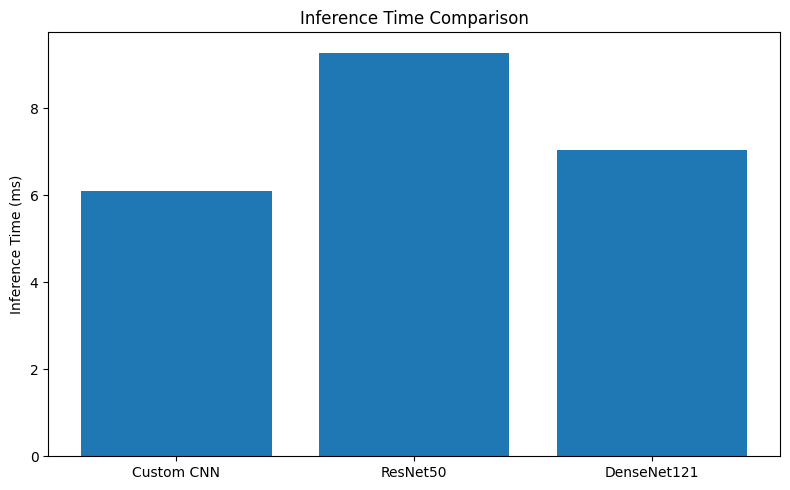

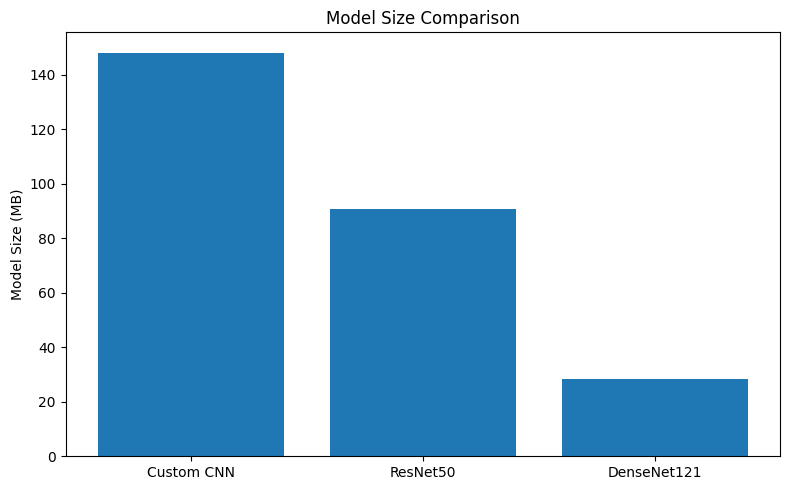

In [11]:
import matplotlib.pyplot as plt
import os
import pandas as pd

efficiency_final = pd.DataFrame({
    "Model": ["Custom CNN", "ResNet50", "DenseNet121"],
    "Parameters": [12938561, 23589761, 70385529],
    "Model Size (MB)": [148.13, 90.65, 28.32],
    "Inference Time (ms)": [6.0973, 9.2746, 7.0417]
})

display(efficiency_final)

# Save table
efficiency_final.to_csv(
    os.path.join(RESULTS_DIR, "model_efficiency_comparison.csv"),
    index=False
)

# Inference time graph
plt.figure(figsize=(8, 5))
plt.bar(
    efficiency_final["Model"],
    efficiency_final["Inference Time (ms)"]
)
plt.ylabel("Inference Time (ms)")
plt.title("Inference Time Comparison")
plt.tight_layout()
plt.savefig(
    os.path.join(RESULTS_DIR, "inference_time_comparison.png"),
    dpi=300
)
plt.show()

# Model size graph
plt.figure(figsize=(8, 5))
plt.bar(
    efficiency_final["Model"],
    efficiency_final["Model Size (MB)"]
)
plt.ylabel("Model Size (MB)")
plt.title("Model Size Comparison")
plt.tight_layout()
plt.savefig(
    os.path.join(RESULTS_DIR, "model_size_comparison.png"),
    dpi=300
)
plt.show()

In [12]:
!pip install -q datasets

README.md:   0%|          | 0.00/7.54k [00:00<?, ?B/s]

Resolving data files:   0%|          | 0/32 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/32 [00:00<?, ?it/s]

Available fields: dict_keys(['image', 'labels', 'label_names', 'image_id', 'fold', 'patient_id', 'follow_up', 'patient_age', 'patient_sex', 'view_position', 'original_width', 'original_height', 'pixel_spacing_x', 'pixel_spacing_y', 'bboxes'])
Image: <PIL.JpegImagePlugin.JpegImageFile image mode=L size=1024x1024 at 0x7A253F1F3770>
Image ID: 00000003_000
Labels: ['Hernia']


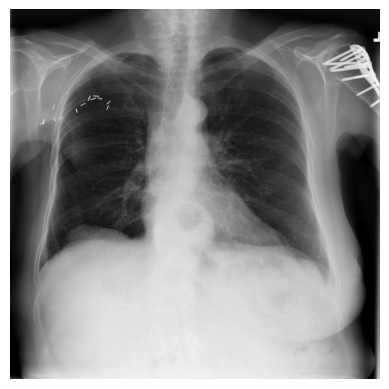

In [13]:
from datasets import load_dataset
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt

# Load the official NIH test split in streaming mode
nih_test = load_dataset(
    "timm/nih-chest-xray-14",
    split="test",
    streaming=True
)

# Inspect one sample to confirm the dataset structure
sample = next(iter(nih_test))

print("Available fields:", sample.keys())
print("Image:", sample["image"])
print("Image ID:", sample.get("image_id"))
print("Labels:", sample.get("label_names"))

plt.imshow(sample["image"], cmap="gray")
plt.axis("off")
plt.show()

In [14]:
from PIL import Image
import numpy as np

TARGET_PER_CLASS = 100
nih_images = []
nih_labels = []
nih_patient_ids = []
nih_image_ids = []

seen_patients = set()
counts = {"Pneumonia": 0, "No Finding": 0}

for i, item in enumerate(nih_test):
    labels = item["label_names"]
    patient_id = item["patient_id"]
    view = item["view_position"]

    # Use frontal X-rays only
    if view not in ["PA", "AP"]:
        continue

    # Avoid multiple images from the same patient
    if patient_id in seen_patients:
        continue

    # Assign binary labels
    if "Pneumonia" in labels:
        class_name = "Pneumonia"
        binary_label = 1
    elif labels == ["No Finding"]:
        class_name = "No Finding"
        binary_label = 0
    else:
        continue

    if counts[class_name] >= TARGET_PER_CLASS:
        continue

    # Prepare image
    image = item["image"].convert("RGB").resize((224, 224))
    image_array = np.array(image, dtype=np.float32)

    nih_images.append(image_array)
    nih_labels.append(binary_label)
    nih_patient_ids.append(patient_id)
    nih_image_ids.append(item["image_id"])

    seen_patients.add(patient_id)
    counts[class_name] += 1

    if counts["Pneumonia"] == TARGET_PER_CLASS and \
       counts["No Finding"] == TARGET_PER_CLASS:
        break

    if (i + 1) % 1000 == 0:
        print(f"Scanned {i+1} images | Counts: {counts}")

X_nih = np.array(nih_images)
y_nih = np.array(nih_labels)

print("\nCollection complete!")
print("Image array shape:", X_nih.shape)
print("Label array shape:", y_nih.shape)
print("Class counts:", counts)
print("Unique patients:", len(set(nih_patient_ids)))


Collection complete!
Image array shape: (100, 224, 224, 3)
Label array shape: (100,)
Class counts: {'Pneumonia': 100, 'No Finding': 0}
Unique patients: 100


In [15]:
from collections import Counter

label_counts = Counter()
empty_labels = 0
no_finding_count = 0
examples = []

for i, item in enumerate(nih_test):
    labels = item["label_names"]

    if not labels:
        empty_labels += 1

    for label in labels:
        label_counts[label] += 1

    if "No Finding" in labels:
        no_finding_count += 1

    if i < 10:
        examples.append({
            "image_id": item["image_id"],
            "labels": labels
        })

print("Label distribution:")
print(label_counts)

print("\nEmpty label count:", empty_labels)
print("No Finding count:", no_finding_count)

print("\nFirst 10 examples:")
for example in examples:
    print(example)

Label distribution:
Counter({'Infiltration': 6112, 'Effusion': 4658, 'Atelectasis': 3279, 'Pneumothorax': 2665, 'Consolidation': 1815, 'Mass': 1748, 'Nodule': 1623, 'Pleural_Thickening': 1143, 'Emphysema': 1093, 'Cardiomegaly': 1069, 'Edema': 925, 'Pneumonia': 555, 'Fibrosis': 435, 'Hernia': 86})

Empty label count: 9861
No Finding count: 0

First 10 examples:
{'image_id': '00000003_000', 'labels': ['Hernia']}
{'image_id': '00000003_001', 'labels': ['Hernia']}
{'image_id': '00000003_002', 'labels': ['Hernia']}
{'image_id': '00000003_003', 'labels': ['Hernia', 'Infiltration']}
{'image_id': '00000003_004', 'labels': ['Hernia']}
{'image_id': '00000003_005', 'labels': ['Hernia']}
{'image_id': '00000003_006', 'labels': ['Hernia']}
{'image_id': '00000003_007', 'labels': ['Hernia']}
{'image_id': '00000013_000', 'labels': []}
{'image_id': '00000013_001', 'labels': ['Emphysema', 'Pneumothorax']}


In [16]:
import numpy as np

TARGET_PER_CLASS = 100

nih_images = []
nih_labels = []
nih_patient_ids = []
nih_image_ids = []

seen_patients = set()
counts = {"Pneumonia": 0, "No Finding": 0}

for item in nih_test:
    labels = item["label_names"]
    patient_id = item["patient_id"]
    view = item["view_position"]

    if view not in ["PA", "AP"]:
        continue

    if patient_id in seen_patients:
        continue

    if "Pneumonia" in labels:
        class_name = "Pneumonia"
        binary_label = 1

    elif len(labels) == 0:
        class_name = "No Finding"
        binary_label = 0

    else:
        continue

    if counts[class_name] >= TARGET_PER_CLASS:
        continue

    image = item["image"].convert("RGB").resize((224, 224))
    image_array = np.array(image, dtype=np.float32)

    nih_images.append(image_array)
    nih_labels.append(binary_label)
    nih_patient_ids.append(patient_id)
    nih_image_ids.append(item["image_id"])

    seen_patients.add(patient_id)
    counts[class_name] += 1

    if all(v == TARGET_PER_CLASS for v in counts.values()):
        break

X_nih = np.array(nih_images)
y_nih = np.array(nih_labels)

print("Image array shape:", X_nih.shape)
print("Label array shape:", y_nih.shape)
print("Class counts:", counts)
print("Unique patients:", len(set(nih_patient_ids)))

Image array shape: (200, 224, 224, 3)
Label array shape: (200,)
Class counts: {'Pneumonia': 100, 'No Finding': 100}
Unique patients: 200


In [17]:
import tensorflow as tf
import pandas as pd
import numpy as np

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# Load the three saved models
custom_cnn = tf.keras.models.load_model(
    "/content/drive/MyDrive/DL MINI PROJECT/models/custom_cnn_best.keras",
    compile=False
)

resnet50 = tf.keras.models.load_model(
    "/content/drive/MyDrive/DL MINI PROJECT/models/resnet50_best.keras",
    compile=False
)

densenet121 = tf.keras.models.load_model(
    "/content/drive/MyDrive/DL MINI PROJECT/results/densenet121/best_densenet121.keras",
    compile=False
)

models = {
    "Custom CNN": custom_cnn,
    "ResNet50": resnet50,
    "DenseNet121": densenet121
}

results = []

# Evaluate each model on the same NIH images
for name, model in models.items():

    probabilities = model.predict(
        X_nih,
        batch_size=32,
        verbose=0
    ).reshape(-1)

    predictions = (probabilities >= 0.5).astype(int)

    metrics = {
        "Model": name,
        "Accuracy": accuracy_score(y_nih, predictions),
        "Precision": precision_score(y_nih, predictions, zero_division=0),
        "Recall": recall_score(y_nih, predictions, zero_division=0),
        "F1 Score": f1_score(y_nih, predictions, zero_division=0),
        "ROC-AUC": roc_auc_score(y_nih, probabilities)
    }

    results.append(metrics)

    print("\n" + "=" * 50)
    print(name)
    print("=" * 50)

    print("\nConfusion Matrix:")
    print(confusion_matrix(y_nih, predictions))

    print("\nClassification Report:")
    print(classification_report(
        y_nih,
        predictions,
        target_names=["No Finding", "Pneumonia"],
        zero_division=0
    ))

nih_results = pd.DataFrame(results)

print("\nEXTERNAL VALIDATION COMPARISON")
display(nih_results.round(4))

ValueError: File not found: filepath=/content/drive/MyDrive/DL MINI PROJECT/models/custom_cnn_best.keras. Please ensure the file is an accessible `.keras` zip file.

In [18]:
import os

from google.colab import drive
drive.mount('/content/drive')

base = "/content/drive/MyDrive"

print("Folders in MyDrive:\n")

for item in os.listdir(base):
    path = os.path.join(base, item)
    if os.path.isdir(path):
        print(repr(item))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Folders in MyDrive:

'Colab Notebooks'
'DL MINI PROJECT'


In [19]:
import os

base = "/content/drive/MyDrive"

target_files = {
    "custom_cnn_best.keras",
    "resnet50_best.keras",
    "best_densenet121.keras"
}

for root, dirs, files in os.walk(base):
    dirs[:] = [
        d for d in dirs
        if d not in {"venv", ".git", "__pycache__"}
    ]

    for filename in files:
        if filename in target_files:
            print(os.path.join(root, filename))

/content/drive/MyDrive/DL MINI PROJECT/results/densenet121/best_densenet121.keras
/content/drive/MyDrive/DL MINI PROJECT/models /custom_cnn_best.keras
/content/drive/MyDrive/DL MINI PROJECT/models /resnet50_best.keras


In [20]:
import tensorflow as tf

BASE = "/content/drive/MyDrive/DL MINI PROJECT"

custom_cnn = tf.keras.models.load_model(
    BASE + "/models /custom_cnn_best.keras",
    compile=False
)

resnet50 = tf.keras.models.load_model(
    BASE + "/models /resnet50_best.keras",
    compile=False
)

densenet121 = tf.keras.models.load_model(
    BASE + "/results/densenet121/best_densenet121.keras",
    compile=False
)

models = {
    "Custom CNN": custom_cnn,
    "ResNet50": resnet50,
    "DenseNet121": densenet121
}

print("All three models loaded successfully!")

for name, model in models.items():
    print(name, "—", model.input_shape)

All three models loaded successfully!
Custom CNN — (None, 224, 224, 3)
ResNet50 — (None, 224, 224, 3)
DenseNet121 — (None, 224, 224, 3)


In [21]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix,
    classification_report
)
import pandas as pd
import numpy as np

results = []

for name, model in models.items():

    probabilities = model.predict(
        X_nih, batch_size=32, verbose=0
    ).reshape(-1)

    predictions = (probabilities >= 0.5).astype(int)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_nih, predictions),
        "Precision": precision_score(y_nih, predictions, zero_division=0),
        "Recall": recall_score(y_nih, predictions, zero_division=0),
        "F1 Score": f1_score(y_nih, predictions, zero_division=0),
        "ROC-AUC": roc_auc_score(y_nih, probabilities)
    })

    print("\n", "=" * 50)
    print(name)
    print("=" * 50)

    print("\nConfusion Matrix:")
    print(confusion_matrix(y_nih, predictions))

    print("\nClassification Report:")
    print(classification_report(
        y_nih,
        predictions,
        target_names=["No Finding", "Pneumonia"],
        zero_division=0
    ))

nih_results = pd.DataFrame(results)

print("\nEXTERNAL VALIDATION RESULTS")
display(nih_results.round(4))


Custom CNN

Confusion Matrix:
[[56 44]
 [41 59]]

Classification Report:
              precision    recall  f1-score   support

  No Finding       0.58      0.56      0.57       100
   Pneumonia       0.57      0.59      0.58       100

    accuracy                           0.57       200
   macro avg       0.58      0.57      0.57       200
weighted avg       0.58      0.57      0.57       200


ResNet50

Confusion Matrix:
[[ 1 99]
 [ 2 98]]

Classification Report:
              precision    recall  f1-score   support

  No Finding       0.33      0.01      0.02       100
   Pneumonia       0.50      0.98      0.66       100

    accuracy                           0.49       200
   macro avg       0.42      0.49      0.34       200
weighted avg       0.42      0.49      0.34       200




DenseNet121

Confusion Matrix:
[[  0 100]
 [  3  97]]

Classification Report:
              precision    recall  f1-score   support

  No Finding       0.00      0.00      0.00       100
   Pneumonia       0.49      0.97      0.65       100

    accuracy                           0.48       200
   macro avg       0.25      0.48      0.33       200
weighted avg       0.25      0.48      0.33       200


EXTERNAL VALIDATION RESULTS


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Custom CNN,0.575,0.5728,0.59,0.5813,0.5592
1,ResNet50,0.495,0.4975,0.98,0.6599,0.6583
2,DenseNet121,0.485,0.4924,0.97,0.6532,0.6482


In [22]:
import numpy as np
import pandas as pd

nih_probs = {}

for name, model in models.items():
    probs = model.predict(
        X_nih, batch_size=32, verbose=0
    ).reshape(-1)

    nih_probs[name] = probs

    normal_probs = probs[y_nih == 0]
    pneumonia_probs = probs[y_nih == 1]

    print("\n", name)
    print("-" * 40)
    print("Mean probability - No Finding:",
          round(normal_probs.mean(), 4))
    print("Mean probability - Pneumonia:",
          round(pneumonia_probs.mean(), 4))
    print("Minimum probability:", round(probs.min(), 4))
    print("Maximum probability:", round(probs.max(), 4))
    print("Predicted Pneumonia (%):",
          round((probs >= 0.5).mean() * 100, 2))


 Custom CNN
----------------------------------------
Mean probability - No Finding: 0.4973
Mean probability - Pneumonia: 0.5787
Minimum probability: 0.007
Maximum probability: 1.0
Predicted Pneumonia (%): 51.5

 ResNet50
----------------------------------------
Mean probability - No Finding: 0.8782
Mean probability - Pneumonia: 0.9251
Minimum probability: 0.3195
Maximum probability: 0.9978
Predicted Pneumonia (%): 98.5

 DenseNet121
----------------------------------------
Mean probability - No Finding: 0.802
Mean probability - Pneumonia: 0.8522
Minimum probability: 0.4783
Maximum probability: 0.9902
Predicted Pneumonia (%): 98.5


In [23]:
import os
import pandas as pd
import numpy as np

RESULTS_DIR = (
    "/content/drive/MyDrive/DL MINI PROJECT/"
    "results/external_validation"
)

os.makedirs(RESULTS_DIR, exist_ok=True)

# Save comparison table
nih_results.to_csv(
    os.path.join(RESULTS_DIR, "nih_external_comparison.csv"),
    index=False
)

# Save individual predictions and probabilities
prediction_data = pd.DataFrame({
    "Image_ID": nih_image_ids,
    "Patient_ID": nih_patient_ids,
    "Actual_Label": y_nih
})

for name, probs in nih_probs.items():
    safe_name = name.lower().replace(" ", "_")
    prediction_data[f"{safe_name}_probability"] = probs
    prediction_data[f"{safe_name}_prediction"] = (
        probs >= 0.5
    ).astype(int)

prediction_data.to_csv(
    os.path.join(RESULTS_DIR, "nih_individual_predictions.csv"),
    index=False
)

print("External validation results saved successfully!")
print("Saved to:", RESULTS_DIR)

External validation results saved successfully!
Saved to: /content/drive/MyDrive/DL MINI PROJECT/results/external_validation
